In [1]:
import pandas as pd

home_df = pd.read_csv(
    "../data/processed/home_kitchen_balanced.csv"
)

print("Shape:", home_df.shape)
print(home_df.columns.tolist())

Shape: (15000, 11)
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase', 'sentiment']


In [2]:
print(home_df["sentiment"].value_counts())

sentiment
positive    5000
neutral     5000
negative    5000
Name: count, dtype: int64


In [ ]:
#SEPRATING OF X AND Y THAT IS X IS REVIWES AND Y IS SENTIMENT
X = home_df["text"].astype(str)
y = home_df["sentiment"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (15000,)
y shape: (15000,)


In [ ]:
#FOR TRAINING AND TESTING DATASET SPLITTING
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 12000
Testing samples: 3000


In [5]:
#CONERTING TEXT INTO NUMERICAL VALUE BY USING TF IDF VECTORIZER
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (12000, 43377)
Testing TF-IDF shape: (3000, 43377)


In [ ]:
#MODEL TRAINING FOR HOME & KITCHEN DOMAIN
from sklearn.linear_model import LogisticRegression

model_home = LogisticRegression(
    max_iter=1000
)

model_home.fit(X_train_tfidf, y_train)

print("Home & Kitchen model trained successfully!")

Home & Kitchen model trained successfully!


In [7]:
y_pred_home = model_home.predict(X_test_tfidf)

print(y_pred_home[:20])

['neutral' 'negative' 'negative' 'negative' 'negative' 'negative'
 'positive' 'neutral' 'negative' 'neutral' 'negative' 'positive' 'neutral'
 'positive' 'positive' 'positive' 'negative' 'positive' 'neutral'
 'positive']


In [8]:
from sklearn.metrics import accuracy_score

accuracy_home = accuracy_score(
    y_test,
    y_pred_home
)

print("Home & Kitchen Accuracy:", round(accuracy_home, 4))

Home & Kitchen Accuracy: 0.699


In [9]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_home
    )
)

              precision    recall  f1-score   support

    negative       0.70      0.66      0.68      1000
     neutral       0.60      0.66      0.62      1000
    positive       0.81      0.78      0.80      1000

    accuracy                           0.70      3000
   macro avg       0.70      0.70      0.70      3000
weighted avg       0.70      0.70      0.70      3000



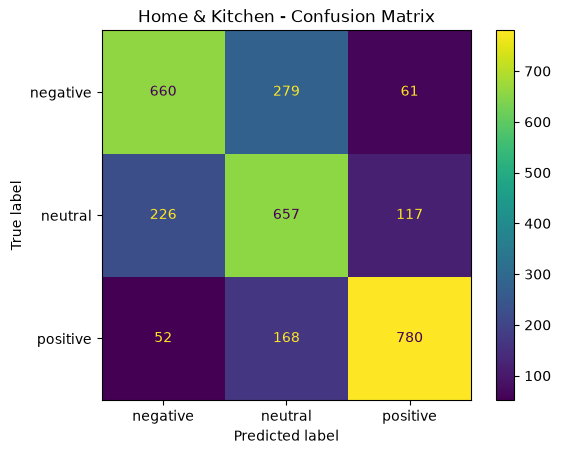

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_home
)

plt.title("Home & Kitchen - Confusion Matrix")
plt.show()

In [11]:
home_results = {
    "domain": "Home & Kitchen",
    "model": "Logistic Regression",
    "accuracy": accuracy_home
}

print(home_results)

{'domain': 'Home & Kitchen', 'model': 'Logistic Regression', 'accuracy': 0.699}


In [12]:
print("Accuracy:", accuracy_home)

Accuracy: 0.699


In [13]:
print(classification_report(y_test, y_pred_home))

              precision    recall  f1-score   support

    negative       0.70      0.66      0.68      1000
     neutral       0.60      0.66      0.62      1000
    positive       0.81      0.78      0.80      1000

    accuracy                           0.70      3000
   macro avg       0.70      0.70      0.70      3000
weighted avg       0.70      0.70      0.70      3000



In [14]:
print(pd.Series(y_pred_home).value_counts())

neutral     1104
positive     958
negative     938
Name: count, dtype: int64


In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_home,
    labels=["negative", "neutral", "positive"]
)

print(cm)

[[660 279  61]
 [226 657 117]
 [ 52 168 780]]


In [16]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0
)

svm_model.fit(X_train_tfidf, y_train)

print("SVM trained successfully!")

SVM trained successfully!


In [17]:
y_pred_svm = svm_model.predict(X_test_tfidf)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

SVM Accuracy: 0.6746666666666666


In [18]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

    negative       0.68      0.65      0.66      1000
     neutral       0.57      0.59      0.58      1000
    positive       0.78      0.78      0.78      1000

    accuracy                           0.67      3000
   macro avg       0.68      0.67      0.68      3000
weighted avg       0.68      0.67      0.68      3000



In [1]:
#for all three datsets
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
#Loading the datasets
home_df = pd.read_csv(
    "../data/processed/home_kitchen_balanced.csv"
)

appliances_df = pd.read_csv(
    "../data/processed/appliances_balanced.csv"
)

sports_df = pd.read_csv(
    "../data/processed/sports_outdoors_balanced.csv"
)

print("Home & Kitchen:", home_df.shape)
print("Appliances:", appliances_df.shape)
print("Sports & Outdoors:", sports_df.shape)

Home & Kitchen: (15000, 11)
Appliances: (15000, 11)
Sports & Outdoors: (15000, 11)


In [ ]:
#training the logistic regression model for each domain
def train_logistic_model(df, domain_name):

    X = df["text"].astype(str)
    y = df["sentiment"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    tfidf = TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95
    )

    X_train_tfidf = tfidf.fit_transform(X_train)
    X_test_tfidf = tfidf.transform(X_test)

    model = LogisticRegression(
        max_iter=1000
    )

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    print("=" * 50)
    print(domain_name)
    print("=" * 50)
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    return {
        "domain": domain_name,
        "model": "Logistic Regression",
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "model_object": model,
        "tfidf": tfidf,
        "X_test": X_test,
        "y_test": y_test,
        "y_pred": y_pred
    }

In [ ]:
#home & kitchen training
home_result = train_logistic_model(
    home_df,
    "Home & Kitchen"
)

Home & Kitchen
Accuracy: 0.699
Macro F1: 0.7008

Classification Report:
              precision    recall  f1-score   support

    negative       0.70      0.66      0.68      1000
     neutral       0.60      0.66      0.62      1000
    positive       0.81      0.78      0.80      1000

    accuracy                           0.70      3000
   macro avg       0.70      0.70      0.70      3000
weighted avg       0.70      0.70      0.70      3000



In [ ]:
appliances_result = train_logistic_model(
    appliances_df,
    "Appliances"
)  # got an error here it says review character was not found

ValueError: np.nan is an invalid document, expected byte or unicode string.

In [ ]:
#checking that which dataset has missing text values and their types
print("Missing text:", appliances_df["text"].isna().sum())
print("Text type:", appliances_df["text"].dtype)
print("Rows:", len(appliances_df))

Missing text: 4
Text type: str
Rows: 15000


In [10]:
#xleaning the dataset
appliances_df["text"] = (
    appliances_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Remove completely empty reviews
appliances_df = appliances_df[
    appliances_df["text"] != ""
].reset_index(drop=True)

print("Rows after cleaning:", len(appliances_df))
print("Missing text:", appliances_df["text"].isna().sum())

Rows after cleaning: 14991
Missing text: 0


In [11]:
appliances_result = train_logistic_model(
    appliances_df,
    "Appliances"
)

Appliances
Accuracy: 0.6626
Macro F1: 0.6637

Classification Report:
              precision    recall  f1-score   support

    negative       0.67      0.69      0.68       999
     neutral       0.54      0.55      0.55      1000
    positive       0.79      0.74      0.76      1000

    accuracy                           0.66      2999
   macro avg       0.67      0.66      0.66      2999
weighted avg       0.67      0.66      0.66      2999



In [ ]:
#for sports and outdoors training
sports_result = train_logistic_model(
    sports_df,
    "Sports & Outdoors"
)

Sports & Outdoors
Accuracy: 0.6787
Macro F1: 0.6772

Classification Report:
              precision    recall  f1-score   support

    negative       0.67      0.70      0.68      1000
     neutral       0.58      0.55      0.56      1000
    positive       0.78      0.79      0.78      1000

    accuracy                           0.68      3000
   macro avg       0.68      0.68      0.68      3000
weighted avg       0.68      0.68      0.68      3000



In [ ]:
#comparison table for all three domains
results = pd.DataFrame([
    {
        "domain": home_result["domain"],
        "model": home_result["model"],
        "accuracy": home_result["accuracy"],
        "macro_f1": home_result["macro_f1"]
    },
    {
        "domain": appliances_result["domain"],
        "model": appliances_result["model"],
        "accuracy": appliances_result["accuracy"],
        "macro_f1": appliances_result["macro_f1"]
    },
    {
        "domain": sports_result["domain"],
        "model": sports_result["model"],
        "accuracy": sports_result["accuracy"],
        "macro_f1": sports_result["macro_f1"]
    }
])

results

,domain,model,accuracy,macro_f1
0,Home & Kitchen,Logistic Regression,0.699000,0.700790
1,Appliances,Logistic Regression,0.662554,0.663736
2,Sports & Outdoors,Logistic Regression,0.678667,0.677193


In [14]:
results.to_csv(
    "../outputs/logistic_regression_results.csv",
    index=False
)

print("Logistic Regression results saved!")

Logistic Regression results saved!


In [ ]:
#linear SVM model training for each domain
from sklearn.svm import LinearSVC

def train_svm_model(df, domain_name):

    X = df["text"].astype(str)
    y = df["sentiment"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    tfidf = TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95
    )

    X_train_tfidf = tfidf.fit_transform(X_train)
    X_test_tfidf = tfidf.transform(X_test)

    svm = LinearSVC(C=1.0)

    svm.fit(X_train_tfidf, y_train)

    y_pred = svm.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    print("=" * 50)
    print(domain_name)
    print("=" * 50)
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    return {
        "domain": domain_name,
        "model": "Linear SVM",
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

In [ ]:
#svm training for home & kitchen domain
home_svm_result = train_svm_model(
    home_df,
    "Home & Kitchen"
)

Home & Kitchen
Accuracy: 0.6747
Macro F1: 0.6754

Classification Report:
              precision    recall  f1-score   support

    negative       0.68      0.65      0.66      1000
     neutral       0.57      0.59      0.58      1000
    positive       0.78      0.78      0.78      1000

    accuracy                           0.67      3000
   macro avg       0.68      0.67      0.68      3000
weighted avg       0.68      0.67      0.68      3000



In [ ]:
#svm training for appliances domain
appliances_svm_result = train_svm_model(
    appliances_df,
    "Appliances"
)

Appliances
Accuracy: 0.6402
Macro F1: 0.6388

Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.67      0.66       999
     neutral       0.53      0.50      0.51      1000
    positive       0.74      0.75      0.74      1000

    accuracy                           0.64      2999
   macro avg       0.64      0.64      0.64      2999
weighted avg       0.64      0.64      0.64      2999



In [ ]:
#svm training for appliances domain
appliances_svm_result = train_svm_model(
    appliances_df,
    "Appliances"
)

Appliances
Accuracy: 0.6402
Macro F1: 0.6388

Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.67      0.66       999
     neutral       0.53      0.50      0.51      1000
    positive       0.74      0.75      0.74      1000

    accuracy                           0.64      2999
   macro avg       0.64      0.64      0.64      2999
weighted avg       0.64      0.64      0.64      2999



In [19]:
sports_svm_result = train_svm_model(
    sports_df,
    "Sports & Outdoors"
)

Sports & Outdoors
Accuracy: 0.6593
Macro F1: 0.6564

Classification Report:
              precision    recall  f1-score   support

    negative       0.65      0.67      0.66      1000
     neutral       0.57      0.52      0.54      1000
    positive       0.74      0.79      0.77      1000

    accuracy                           0.66      3000
   macro avg       0.65      0.66      0.66      3000
weighted avg       0.65      0.66      0.66      3000



In [ ]:
#final comparison of logistic regression and svm results for all three domains
comparison_results = pd.DataFrame([
    {
        "domain": home_result["domain"],
        "Logistic Regression Accuracy": home_result["accuracy"],
        "Logistic Regression Macro F1": home_result["macro_f1"],
        "SVM Accuracy": home_svm_result["accuracy"],
        "SVM Macro F1": home_svm_result["macro_f1"]
    },
    {
        "domain": appliances_result["domain"],
        "Logistic Regression Accuracy": appliances_result["accuracy"],
        "Logistic Regression Macro F1": appliances_result["macro_f1"],
        "SVM Accuracy": appliances_svm_result["accuracy"],
        "SVM Macro F1": appliances_svm_result["macro_f1"]
    },
    {
        "domain": sports_result["domain"],
        "Logistic Regression Accuracy": sports_result["accuracy"],
        "Logistic Regression Macro F1": sports_result["macro_f1"],
        "SVM Accuracy": sports_svm_result["accuracy"],
        "SVM Macro F1": sports_svm_result["macro_f1"]
    }
])

comparison_results

,domain,Logistic Regression Accuracy,Logistic Regression Macro F1,SVM Accuracy,SVM Macro F1
0,Home & Kitchen,0.699000,0.700790,0.674667,0.675375
1,Appliances,0.662554,0.663736,0.640213,0.638848
2,Sports & Outdoors,0.678667,0.677193,0.659333,0.656392


In [21]:
comparison_results.to_csv(
    "../outputs/logistic_vs_svm_results.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [ ]:
#cross domain testing function  that is training on one domain and testing on another domain
def cross_domain_test(train_df, test_df, train_domain, test_domain):

    X_train = train_df["text"].fillna("").astype(str)
    y_train = train_df["sentiment"]

    X_test = test_df["text"].fillna("").astype(str)
    y_test = test_df["sentiment"]

    tfidf = TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95
    )

    X_train_tfidf = tfidf.fit_transform(X_train)
    X_test_tfidf = tfidf.transform(X_test)

    model = LogisticRegression(max_iter=1000)

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    print("=" * 55)
    print(f"Train: {train_domain} → Test: {test_domain}")
    print("=" * 55)
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    return {
        "train_domain": train_domain,
        "test_domain": test_domain,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

In [24]:
home_to_appliances = cross_domain_test(
    home_df,
    appliances_df,
    "Home & Kitchen",
    "Appliances"
)

Train: Home & Kitchen → Test: Appliances
Accuracy: 0.6158
Macro F1: 0.6114


In [25]:
appliances_to_home = cross_domain_test(
    appliances_df,
    home_df,
    "Appliances",
    "Home & Kitchen"
)

Train: Appliances → Test: Home & Kitchen
Accuracy: 0.6212
Macro F1: 0.6268


In [26]:
home_to_sports = cross_domain_test(
    home_df,
    sports_df,
    "Home & Kitchen",
    "Sports & Outdoors"
)

Train: Home & Kitchen → Test: Sports & Outdoors
Accuracy: 0.6311
Macro F1: 0.6351


In [27]:
sports_to_home = cross_domain_test(
    sports_df,
    home_df,
    "Sports & Outdoors",
    "Home & Kitchen"
)

Train: Sports & Outdoors → Test: Home & Kitchen
Accuracy: 0.668
Macro F1: 0.6686


In [28]:
appliances_to_sports = cross_domain_test(
    appliances_df,
    sports_df,
    "Appliances",
    "Sports & Outdoors"
)

Train: Appliances → Test: Sports & Outdoors
Accuracy: 0.6129
Macro F1: 0.6187


In [29]:
sports_to_appliances = cross_domain_test(
    sports_df,
    appliances_df,
    "Sports & Outdoors",
    "Appliances"
)

Train: Sports & Outdoors → Test: Appliances
Accuracy: 0.6236
Macro F1: 0.6201


In [30]:
cross_domain_results = pd.DataFrame([
    home_to_appliances,
    appliances_to_home,
    home_to_sports,
    sports_to_home,
    appliances_to_sports,
    sports_to_appliances
])

cross_domain_results

,train_domain,test_domain,accuracy,macro_f1
0,Home & Kitchen,Appliances,0.615836,0.611360
1,Appliances,Home & Kitchen,0.621200,0.626843
2,Home & Kitchen,Sports & Outdoors,0.631067,0.635104
3,Sports & Outdoors,Home & Kitchen,0.668000,0.668612
4,Appliances,Sports & Outdoors,0.612867,0.618737
5,Sports & Outdoors,Appliances,0.623641,0.620091


In [31]:
cross_domain_results.to_csv(
    "../outputs/cross_domain_results.csv",
    index=False
)

print("Cross-domain results saved!")

Cross-domain results saved!


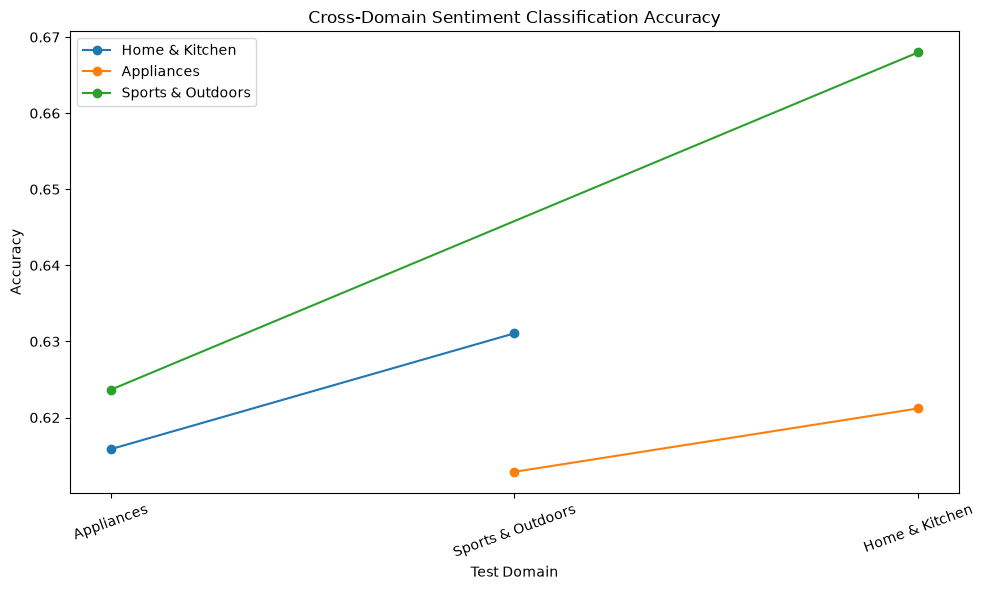

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for train_domain in cross_domain_results["train_domain"].unique():
    subset = cross_domain_results[
        cross_domain_results["train_domain"] == train_domain
    ]

    plt.plot(
        subset["test_domain"],
        subset["accuracy"],
        marker="o",
        label=train_domain
    )

plt.title("Cross-Domain Sentiment Classification Accuracy")
plt.xlabel("Test Domain")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()